In [1]:
# ==============================================================================
# INSTALASI DEPENDENSI (Jalankan sel ini HANYA jika pustaka belum terpasang)
# Hilangkan tanda pagar (#) pada baris di bawah untuk memasang dependensi:
# ==============================================================================
# !pip install numpy pandas matplotlib scipy scikit-learn rasterio catboost imbalanced-learn
# Atau instal seluruh dependensi modul melalui file requirements.txt:
# !pip install -r ../../requirements.txt

# Praktik 5. Machine Learning untuk Digital Soil Mapping

Notebook ini memetakan **tutupan material**, yaitu bahan induk tanah (*parent material*), di Sub-DAS Bompon dengan pembelajaran mesin (*machine learning*). Sasarannya kategorik: tujuh kelas material pada peta Malik (2017), yang juga dipakai Fatmawati (2026) sebagai kovariat bahan induk. Alurnya mengikuti persamaan SCORPAN pada Modul 8: mempelajari hubungan antara kelas di titik sampel dan kondisi lingkungannya, menilai hubungan itu secara jujur, lalu menerapkannya ke seluruh piksel.

Model utama adalah **CatBoost** (Prokhorenkova et al., 2018), algoritme *gradient boosting* yang dapat membaca kovariat kategorik secara langsung. *Random forest* dipakai sebagai pembanding.

Notebook dibagi menjadi tiga bagian:

- **Bagian A**, Machine Learning untuk DSM;
- **Bagian B**, penyiapan dan pemilihan kovariat berdasarkan SCORPAN;
- **Bagian C**, pembangunan model DSM.

Satu hal perlu dipegang sejak awal: kelas di 210 titik diambil dari **peta**, bukan dari pengamatan lapangan. Ukuran ketelitian di notebook ini menyatakan seberapa baik model mereproduksi peta Malik (2017) dari kovariat, bukan seberapa benar peta itu di lapangan.

## Menyiapkan lingkungan kerja

In [2]:
import os, sys

# Di Google Colab: pasang pustaka lalu sambungkan Drive. Di Jupyter lokal bagian ini dilewati.
if 'google.colab' in sys.modules:
    !pip -q install numpy pandas scipy scikit-learn matplotlib rasterio catboost imbalanced-learn
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/Pelatihan/data/praktik-5')   # sesuaikan dengan lokasi folder Anda

os.makedirs('hasil', exist_ok=True)
print('Folder kerja:', os.path.basename(os.getcwd()))

Folder kerja: praktik-5


In [3]:
import glob
import shutil
import textwrap
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import rasterio
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE, SMOTENC
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import GroupKFold, StratifiedKFold, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

# Bagian A. Machine Learning untuk DSM

## A1. Membaca titik sampel dan kovariat

Berkas `titik_tutupan_material.csv` memuat 210 titik, 30 titik untuk setiap kelas. Titik ditempatkan di pusat sel grid kovariat 10 m, sekurang-kurangnya 15 m di dalam poligon kelasnya, dan disebar merata di setiap kelas. Kolom `subset` membagi titik menjadi 21 titik latih (*training data*) dan 9 titik uji (*test data*) per kelas. Folder `kovariat/` berisi satu GeoTIFF untuk setiap kovariat, sedangkan `material_acuan_10m.tif` adalah peta Malik (2017) pada grid yang sama, yang hanya dipakai sebagai pembanding.

In [4]:
titik = pd.read_csv('titik_tutupan_material.csv')
jalur = sorted(glob.glob('kovariat/*.tif'))
nama_kov = [os.path.basename(p)[:-4] for p in jalur]
susunan = []
for p in jalur:
    with rasterio.open(p) as r:
        susunan.append(r.read(1).astype('float32'))
        transform, crs, tinggi, lebar, batas_grid = r.transform, r.crs, r.height, r.width, r.bounds
kubus = np.stack(susunan)      # kovariat x baris x kolom
with rasterio.open('material_acuan_10m.tif') as r:
    acuan = r.read(1)
dalam = kubus[nama_kov.index('kat_bentuklahan')] > 0     # piksel di dalam Sub-DAS

KELAS = titik.drop_duplicates('kode').set_index('kode')['material'].sort_index()
WARNA = {1: '#E69F00', 2: '#56B4E9', 3: '#0072B2', 4: '#009E73', 5: '#F0E442', 6: '#D55E00', 7: '#CC79A7'}
PETA_WARNA = ListedColormap([WARNA[k] for k in KELAS.index])
luas_ha = pd.Series(np.bincount(acuan[dalam], minlength=len(KELAS) + 1)[1:] * 100 / 1e4, index=KELAS.index)
y = titik['kode'].values

print('Titik    :', len(titik))
print('Kovariat :', len(nama_kov), nama_kov)
print('Grid     :', kubus.shape[1:], '| CRS', crs)
pd.DataFrame({'Material': KELAS, 'Titik': titik['kode'].value_counts().sort_index(),
              'Luas pada peta (ha)': luas_ha.round(1), 'Luas (%)': (100 * luas_ha / luas_ha.sum()).round(1)})

Titik    : 210
Kovariat : 16 ['arah_utara', 'bi_2024', 'bsi_2024', 'cmr_2024', 'elevasi', 'jarak_sungai', 'kat_bentuklahan', 'kat_penggunaan_lahan', 'lereng', 'ndvi_2024', 'ndvi_2025', 'sar_vh', 'sar_vv', 'tpi', 'tri', 'twi']
Grid     : (362, 192) | CRS EPSG:32749


,Material,Titik,Luas pada peta (ha),Luas (%)
kode,,,,
1,Breksi andesit sisipan diorit,30,9.7,3.3
2,Breksi andesit teralterasi,30,75.5,25.6
3,"Breksi andesit teralterasi, ditumpangi lapukan...",30,38.2,13.0
4,Breksi vulkanik,30,39.8,13.5
5,"Endapan material Sumbing Muda, pasir tufan, tu...",30,67.4,22.9
6,Endapan Sumbing Muda dan endapan material longsor,30,35.4,12.0
7,Tuff pasiran,30,28.7,9.7


Perhatikan bahwa setiap kelas memiliki 30 titik, padahal luasnya sangat berbeda. Kelas 1 hanya sekitar 3% wilayah, sedangkan kelas 2 sekitar seperempatnya. Akibat rancangan sampel seimbang (*balanced sampling*) ini dibahas pada Bagian C5 dan C6.

## A2. Mengambil nilai kovariat di titik sampel

Langkah ini disebut penumpangan (*overlay*). Hasilnya adalah tabel pemodelan: satu baris per titik, berisi kelas material dan semua nilai kovariat. Tabel di bawah menampilkan median setiap kovariat numerik per kelas.

In [5]:
baris, kolom = rasterio.transform.rowcol(transform, titik['x'].values, titik['y'].values)
tabel = pd.DataFrame(kubus[:, np.array(baris), np.array(kolom)].T, columns=nama_kov)
tabel.insert(0, 'kode', y)
tabel.to_csv('hasil/tabel_kovariat_di_titik.csv', index=False)
numerik = [k for k in nama_kov if not k.startswith('kat_')]
tabel.groupby('kode')[numerik].median().T.round(2)

kode,1,2,3,4,5,6,7
arah_utara,-0.130000,-0.180000,0.190000,0.200000,-0.260000,-0.750000,-0.300000
bi_2024,0.030000,0.030000,0.030000,0.030000,0.030000,0.060000,0.030000
bsi_2024,-0.280000,-0.270000,-0.240000,-0.250000,-0.260000,-0.070000,-0.250000
cmr_2024,2.300000,2.270000,2.160000,2.240000,2.260000,1.770000,2.240000
elevasi,445.690002,455.369995,448.179993,457.119995,458.140015,426.380005,474.070007
jarak_sungai,55.000000,116.980003,190.759995,114.080002,138.330002,40.000000,136.720001
lereng,18.780001,18.969999,23.770000,21.490000,19.230000,8.900000,23.180000
ndvi_2024,0.850000,0.830000,0.840000,0.830000,0.840000,0.520000,0.830000
ndvi_2025,0.880000,0.880000,0.870000,0.870000,0.880000,0.670000,0.880000
sar_vh,-11.240000,-12.590000,-13.320000,-13.650000,-12.220000,-16.219999,-13.500000


## A3. Model pertama: latih, uji, dan bahaya *overfitting*

Pakai pembagian yang sudah disiapkan di kolom `subset`: 147 titik latih dan 63 titik uji. Latih CatBoost dengan kovariat numerik saja, lalu bandingkan ketelitiannya pada data latih dan data uji.

**Akurasi keseluruhan** (*overall accuracy*, OA) adalah proporsi titik yang kelasnya ditebak benar. Karena ada tujuh kelas dengan jumlah titik sama, menebak sembarang hanya memberi akurasi sekitar 1/7 = 0,14. **Kappa Cohen** (*Cohen's kappa*) menyatakan seberapa jauh akurasi melampaui kesepakatan yang terjadi karena kebetulan (*chance agreement*). **Presisi makro**, **recall makro**, dan **F1 makro** (*macro-averaged precision, recall, and F1-score*) adalah rata-rata presisi, recall, dan F1 ketujuh kelas, sehingga kelas yang selalu salah ikut menurunkan nilainya. Arti presisi dan recall setiap kelas dijelaskan pada Bagian C3.

In [6]:
def ukuran(y, p):
    return {'Akurasi': accuracy_score(y, p), 'Kappa': cohen_kappa_score(y, p),
            'Presisi makro': precision_score(y, p, average='macro', zero_division=0),
            'Recall makro': recall_score(y, p, average='macro', zero_division=0),
            'F1 makro': f1_score(y, p, average='macro', zero_division=0)}

PENGATURAN_CATBOOST = dict(iterations=300, depth=4, learning_rate=0.08, one_hot_max_size=10, random_seed=0, verbose=0, allow_writing_files=False)

def catboost_baru(**atur):
    """CatBoost dengan pengaturan yang sama di seluruh notebook; atur menimpa pengaturan bawaan."""
    return CatBoostClassifier(**{**PENGATURAN_CATBOOST, **atur})

latih = (titik['subset'] == 'latih').values
cb = catboost_baru().fit(tabel.loc[latih, numerik], y[latih])
pd.DataFrame({'Data latih': ukuran(y[latih], cb.predict(tabel.loc[latih, numerik]).ravel()),
              'Data uji': ukuran(y[~latih], cb.predict(tabel.loc[~latih, numerik]).ravel())}).T.round(2)

,Akurasi,Kappa,Presisi makro,Recall makro,F1 makro
Data latih,1.00,1.00,1.00,1.00,1.00
Data uji,0.54,0.46,0.51,0.54,0.51


**Diskusi.** Ketelitian pada data latih hampir selalu indah karena model menghafal. Hanya angka pada data uji yang boleh dibaca sebagai kemampuan model. Pembagian tunggal (*single train-test split*) juga rapuh, karena hasilnya bergantung pada titik yang kebetulan terpilih sebagai data uji. Sel berikut mengulang pembagian 70/30 secara acak sebanyak 30 kali.

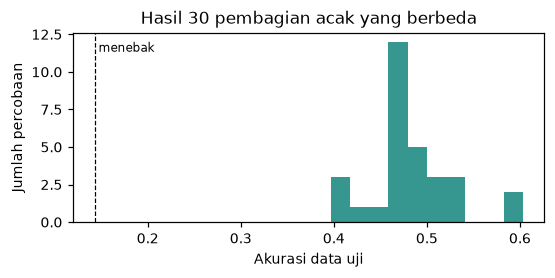

Akurasi terendah 0.40, median 0.48, tertinggi 0.60


In [7]:
hasil = []
for acak in range(30):
    a, b = train_test_split(np.arange(len(y)), test_size=.3, stratify=y, random_state=acak)
    m = catboost_baru().fit(tabel.loc[a, numerik], y[a])
    hasil.append(accuracy_score(y[b], m.predict(tabel.loc[b, numerik]).ravel()))
plt.figure(figsize=(5, 2.6)); plt.hist(hasil, bins=10, color='#35978f')
plt.axvline(1 / 7, color='k', ls='--', lw=.8); plt.text(1 / 7, plt.ylim()[1] * .9, ' menebak', fontsize=8)
plt.xlabel('Akurasi data uji'); plt.ylabel('Jumlah percobaan'); plt.title('Hasil 30 pembagian acak yang berbeda')
plt.tight_layout(); plt.savefig('hasil/sebaran_akurasi_pembagian_tunggal.png', dpi=150); plt.show()
print(f'Akurasi terendah {min(hasil):.2f}, median {np.median(hasil):.2f}, tertinggi {max(hasil):.2f}')

# Bagian B. Penyiapan dan pemilihan kovariat

## B1. Memetakan kovariat ke faktor SCORPAN

Kali ini sasaran pemodelan adalah faktor **p**, yaitu bahan induk itu sendiri. Karena itu peta material tidak dapat dipakai sebagai kovariat. Yang dipelajari adalah seberapa jauh faktor lain, terutama relief (r) dan data penginderaan jauh (o, s), mencerminkan material di bawahnya. Kolom terakhir adalah alasan geomorfologis atau pedologisnya. Alasan itu adalah hipotesis yang belum tentu terbukti pada data ini.

In [8]:
faktor = pd.DataFrame([
    ('elevasi', 'r', 'DEMNAS', 'Satuan material menempati posisi yang berbeda dalam lanskap'),
    ('lereng', 'r', 'DEMNAS', 'Batuan yang tahan pelapukan cenderung membentuk lereng terjal'),
    ('tpi', 'r', 'DEMNAS', 'Punggungan dan lembah; endapan mengisi bagian yang rendah'),
    ('tri', 'r', 'DEMNAS', 'Kekasaran medan yang dipengaruhi ketahanan batuan'),
    ('twi', 'r', 'DEMNAS', 'Zona penerimaan aliran dan penimbunan endapan'),
    ('arah_utara', 'r', 'DEMNAS', 'Arah hadap; kaitannya dengan material diduga lemah'),
    ('jarak_sungai', 'r', 'Peta sungai', 'Endapan longsor dan koluvial berada di sepanjang alur'),
    ('kat_bentuklahan', 'r', 'Peta riset', 'Bentuklahan mencerminkan proses dan bahan penyusunnya'),
    ('kat_penggunaan_lahan', 'o', 'Foto udara', 'Penggunaan lahan dapat mengikuti kondisi tanah dari material'),
    ('ndvi_2024', 'o', 'Sentinel-2', 'Kerapatan vegetasi yang mungkin berbeda menurut material'),
    ('ndvi_2025', 'o', 'Sentinel-2', 'Kerapatan vegetasi yang mungkin berbeda menurut material'),
    ('bsi_2024', 'o/s', 'Sentinel-2', 'Keterbukaan tanah'),
    ('bi_2024', 'o/s', 'Sentinel-2', 'Kecerahan permukaan, terkait warna tanah bila terbuka'),
    ('cmr_2024', 'o/s', 'Sentinel-2', 'Rasio SWIR yang peka terhadap mineral lempung hasil alterasi'),
    ('sar_vv', 'o/r', 'Sentinel-1', 'Kekasaran dan kelembapan permukaan, bentuk medan'),
    ('sar_vh', 'o', 'Sentinel-1', 'Hamburan volume vegetasi'),
], columns=['Kovariat', 'Faktor', 'Sumber', 'Alasan'])
faktor

,Kovariat,Faktor,Sumber,Alasan
0,elevasi,r,DEMNAS,Satuan material menempati posisi yang berbeda ...
1,lereng,r,DEMNAS,Batuan yang tahan pelapukan cenderung membentu...
2,tpi,r,DEMNAS,Punggungan dan lembah; endapan mengisi bagian ...
3,tri,r,DEMNAS,Kekasaran medan yang dipengaruhi ketahanan batuan
4,twi,r,DEMNAS,Zona penerimaan aliran dan penimbunan endapan
5,arah_utara,r,DEMNAS,Arah hadap; kaitannya dengan material diduga l...
6,jarak_sungai,r,Peta sungai,Endapan longsor dan koluvial berada di sepanja...
7,kat_bentuklahan,r,Peta riset,Bentuklahan mencerminkan proses dan bahan peny...
8,kat_penggunaan_lahan,o,Foto udara,Penggunaan lahan dapat mengikuti kondisi tanah...
9,ndvi_2024,o,Sentinel-2,Kerapatan vegetasi yang mungkin berbeda menuru...


## B2. Korelasi Pearson antarkovariat

Kovariat yang sangat mirip membawa informasi yang hampir sama. Korelasi Pearson (*Pearson correlation coefficient*, r) mengukur kemiripan linear dua kovariat, dari −1 sampai 1. Korelasi dihitung dari seluruh piksel di dalam Sub-DAS, bukan dari 210 titik saja, agar stabil. Pasangan dengan |r| ≥ 0,8 dicatat di sini, tetapi belum dibuang. Kovariat mana yang dipertahankan dari setiap pasangan diputuskan pada Bagian C4, setelah tingkat kepentingannya bagi model diketahui.

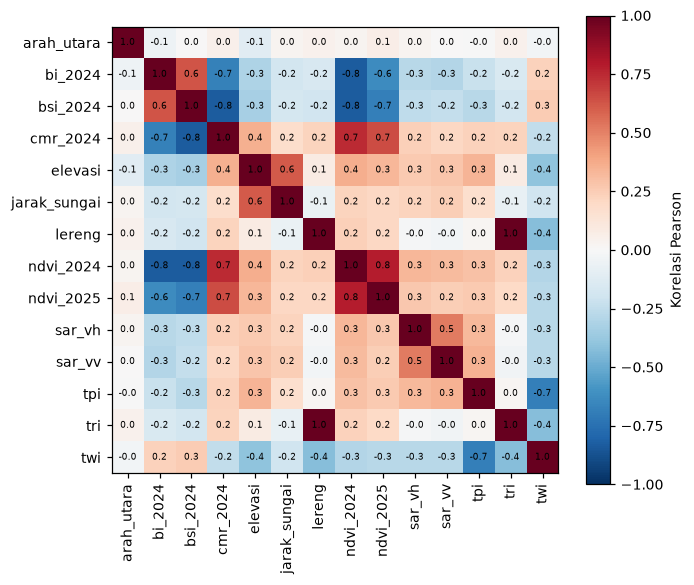

,Kovariat 1,Kovariat 2,r Pearson
0,bi_2024,ndvi_2024,-0.83
1,bsi_2024,cmr_2024,-0.83
2,bsi_2024,ndvi_2024,-0.83
3,lereng,tri,0.99


In [9]:
piksel = pd.DataFrame(kubus[:, dalam].T, columns=nama_kov)
r_pix = piksel[numerik].corr(method='pearson')

fig, ax = plt.subplots(figsize=(6.4, 5.4))
g = ax.imshow(r_pix, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(numerik)), numerik, rotation=90); ax.set_yticks(range(len(numerik)), numerik)
for i in range(len(numerik)):
    for j in range(len(numerik)):
        ax.text(j, i, f'{r_pix.iloc[i, j]:.1f}', ha='center', va='center', fontsize=6)
plt.colorbar(g, label='Korelasi Pearson'); plt.tight_layout(); plt.savefig('hasil/korelasi_kovariat.png', dpi=150); plt.show()

AMBANG_R = 0.8
pasangan = [(a, b, r_pix.loc[a, b]) for i, a in enumerate(numerik) for b in numerik[i + 1:] if abs(r_pix.loc[a, b]) >= AMBANG_R]
pd.DataFrame(pasangan, columns=['Kovariat 1', 'Kovariat 2', 'r Pearson']).round(2)

## B3. Kovariat kategorik

Bentuklahan dan penggunaan lahan adalah kategori, bukan angka. Kode 1 sampai 6 pada `kat_bentuklahan` hanyalah nama, sehingga Dataran Koluvial (6) tidak "lebih besar" daripada Interfluve (1). Ada dua cara memasukkannya ke model:

1. **One-hot** (*one-hot encoding*), yaitu setiap kelas kategori menjadi kolom 0/1 tersendiri. Cara ini diperlukan oleh *random forest* di scikit-learn.
2. **Langsung sebagai kategori** (*native categorical feature handling*), yaitu kolom berisi nama kelas dan model mengolahnya sendiri. Inilah keunggulan CatBoost. Kategori dengan sedikit nilai dikodekan *one-hot* di dalam model (parameter `one_hot_max_size`), sedangkan kategori dengan banyak nilai, misalnya kode blok kebun, diubah menjadi statistik sasaran berurutan (*ordered target statistics*) yang dirancang agar nilai sasaran tidak bocor ke dalam model (Prokhorenkova et al., 2018).

Sel berikut menyiapkan kedua bentuk tabel dan memeriksa sebaran titik per kategori.

In [10]:
LABEL = {'kat_bentuklahan': {1: 'Interfluve', 2: 'Lereng Atas', 3: 'Lereng Tengah', 4: 'Lereng Bawah', 5: 'Lereng Kaki Koluvial', 6: 'Dataran Koluvial'},
         'kat_penggunaan_lahan': {1: 'Agroforestri', 2: 'Tegalan', 3: 'Sawah', 4: 'Permukiman'}}
KAT = list(LABEL)

def siapkan_X(df, kolom):
    """Tabel prediktor untuk CatBoost: kovariat numerik apa adanya, kategori sebagai nama kelas."""
    X = df[kolom].copy()
    for k in kolom:
        if k in KAT:
            X[k] = df[k].astype(int).map(LABEL[k])
    return X

def satu_panas(X):
    """Tabel prediktor untuk random forest: setiap kelas kategori menjadi kolom 0/1."""
    X = X.copy()
    for k in [c for c in X.columns if c in KAT]:
        for nilai in LABEL[k].values():
            X[f'{k}={nilai}'] = (X[k] == nilai).astype(float)
        X = X.drop(columns=k)
    return X

semua = numerik + KAT
X_semua = siapkan_X(tabel, semua)
print('Tabel CatBoost:', X_semua.shape, '| tabel random forest (one-hot):', satu_panas(X_semua).shape)
print('Titik per penggunaan lahan:', X_semua['kat_penggunaan_lahan'].value_counts().to_dict())
pd.crosstab(X_semua['kat_bentuklahan'], titik['kode'].rename('kelas material'), margins=True, margins_name='Jumlah')

Tabel CatBoost: (210, 16) | tabel random forest (one-hot): (210, 24)
Titik per penggunaan lahan: {'Agroforestri': 149, 'Sawah': 27, 'Permukiman': 21, 'Tegalan': 13}


kelas material,1,2,3,4,5,6,7,Jumlah
kat_bentuklahan,,,,,,,,
Dataran Koluvial,0,0,0,0,0,18,0,18
Interfluve,6,4,2,1,5,0,2,20
Lereng Atas,7,6,5,7,10,0,8,43
Lereng Bawah,8,5,8,3,4,0,7,35
Lereng Kaki Koluvial,0,0,1,0,0,12,0,13
Lereng Tengah,9,15,14,19,11,0,13,81
Jumlah,30,30,30,30,30,30,30,210


# Bagian C. Pembangunan model DSM

## C1. Skema validasi

Tiga skema validasi silang (*cross-validation*) dibandingkan:

1. **Acak** (*stratified random k-fold cross-validation*), yaitu titik dibagi acak ke dalam lima lipatan (*fold*) dengan jumlah per kelas yang seimbang.
2. **Blok spasial** (*spatial block cross-validation*), yaitu wilayah dibagi menjadi blok persegi 400 m dan setiap blok utuh masuk ke satu lipatan. Titik uji tidak memiliki tetangga dekat di data latih, tetapi kelas yang sama masih terwakili di blok lain.
3. **Zona** (*leave-cluster-out cross-validation*), yaitu titik dikelompokkan menjadi lima zona besar dengan *k-means*. Skema ini meniru penerapan model ke wilayah yang benar-benar baru, misalnya kebun tetangga.

Rujukan konsepnya ada pada Modul 8, Gambar 8.2.

Acak          titik uji per lipatan [42, 42, 42, 42, 42] | kelas yang tidak ada di data latih: [[], [], [], [], []]
Blok spasial  titik uji per lipatan [42, 42, 42, 42, 42] | kelas yang tidak ada di data latih: [[], [], [], [], []]
Zona          titik uji per lipatan [58, 50, 40, 34, 28] | kelas yang tidak ada di data latih: [[], [7], [], [], []]


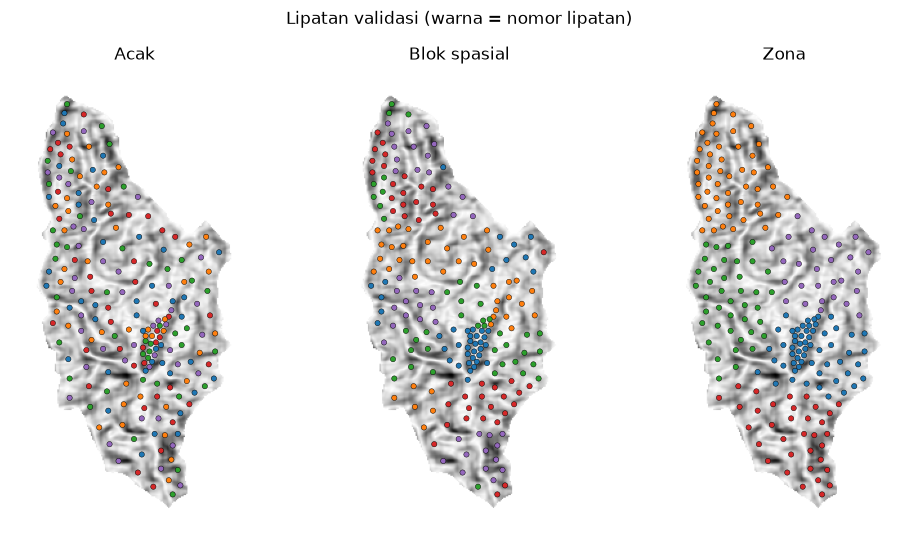

In [11]:
SISI_BLOK = 400
blok = (np.floor((titik['x'].values - batas_grid.left) / SISI_BLOK).astype(int) * 100
        + np.floor((titik['y'].values - batas_grid.bottom) / SISI_BLOK).astype(int))
zona = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(titik[['x', 'y']])
iris = {'Acak': list(StratifiedKFold(5, shuffle=True, random_state=0).split(tabel, y)),
        'Blok spasial': list(GroupKFold(5).split(tabel, y, groups=blok)),
        'Zona': list(GroupKFold(5).split(tabel, y, groups=zona))}

fig, ax = plt.subplots(1, 3, figsize=(9, 5))
latar = np.where(dalam, kubus[nama_kov.index('lereng')], np.nan)
luasan = [batas_grid.left, batas_grid.right, batas_grid.bottom, batas_grid.top]
for a, (skema, lipatan) in zip(ax, iris.items()):
    nomor = np.zeros(len(y), int)
    for i, (_, uji) in enumerate(lipatan):
        nomor[uji] = i
    a.imshow(latar, extent=luasan, cmap='Greys'); a.scatter(titik.x, titik.y, c=nomor, cmap='tab10', vmin=0, vmax=9, s=12, edgecolor='k', lw=.3)
    a.set_title(skema); a.axis('off')
    hilang = [sorted(set(KELAS.index) - set(y[latih])) for latih, _ in lipatan]
    print(f'{skema:13s} titik uji per lipatan {[len(u) for _, u in lipatan]} | kelas yang tidak ada di data latih: {hilang}')
plt.suptitle('Lipatan validasi (warna = nomor lipatan)'); plt.tight_layout(); plt.savefig('hasil/skema_validasi.png', dpi=150); plt.show()

## C2. Membandingkan model dengan pembanding sederhana

Model harus dibandingkan dengan sesuatu. Ada dua pembanding sederhana (*baseline*):

1. **Kelas terbanyak** (*majority class*), yaitu selalu menebak kelas yang paling banyak di data latih.
2. **Kelas terbanyak per bentuklahan**, yaitu setiap bentuklahan diberi satu kelas material, seperti satuan pada peta konvensional.

Setelah itu, *random forest* (dengan *one-hot*) dan CatBoost dilatih dengan ke-16 kovariat. Jika model yang rumit tidak mengalahkan pembanding sederhana, kerumitan itu belum memberi manfaat.

In [12]:
class KelasTerbanyak:
    def fit(self, X, y):
        self.kelas = pd.Series(y).mode()[0]; return self
    def predict(self, X):
        return np.full(len(X), self.kelas)

class KelasPerBentuklahan:
    """Satu kelas material untuk setiap bentuklahan, seperti satuan pada peta konvensional."""
    def fit(self, X, y):
        s = pd.Series(y, index=X.index)
        self.umum = s.mode()[0]
        self.peta = s.groupby(X['kat_bentuklahan']).agg(lambda v: v.mode()[0]).to_dict()
        return self
    def predict(self, X):
        return X['kat_bentuklahan'].map(self.peta).fillna(self.umum).astype(int).values

class RFSatuPanas:
    """Random forest; kategori diubah menjadi one-hot lebih dulu."""
    def fit(self, X, y):
        self.m = RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1).fit(satu_panas(X), y)
        self.classes_ = self.m.classes_; return self
    def predict(self, X):
        return self.m.predict(satu_panas(X))
    def predict_proba(self, X):
        return self.m.predict_proba(satu_panas(X))

class CatBoostKategori:
    """CatBoost yang membaca kolom kategori secara langsung."""
    def __init__(self, **atur):
        self.atur = atur
    def fit(self, X, y):
        self.m = catboost_baru(**self.atur).fit(X, y, cat_features=[k for k in X.columns if k in KAT])
        self.classes_ = self.m.classes_; return self
    def predict(self, X):
        return self.m.predict(X).ravel()
    def predict_proba(self, X):
        return self.m.predict_proba(X)

def validasi(buat_model, kolom, skema):
    """Validasi silang: prediksi dan peluang setiap titik saat lipatannya disisihkan, beserta model tiap lipatan."""
    X = siapkan_X(tabel, kolom)
    p, peluang, model = np.zeros(len(y), int), np.zeros((len(y), len(KELAS))), []
    for latih, uji in iris[skema]:
        m = buat_model().fit(X.iloc[latih], y[latih])
        p[uji] = m.predict(X.iloc[uji])
        if hasattr(m, 'predict_proba'):
            peluang[np.ix_(uji, np.asarray(m.classes_) - 1)] = m.predict_proba(X.iloc[uji])
        model.append(m)
    return p, peluang, model

MODEL = {'Kelas terbanyak': KelasTerbanyak, 'Kelas terbanyak per bentuklahan': KelasPerBentuklahan,
         'Random forest (one-hot)': RFSatuPanas, 'CatBoost': CatBoostKategori}
hasil_cv, baris = {}, []
for nama, buat in MODEL.items():
    for skema in iris:
        hasil_cv[(nama, skema)] = validasi(buat, semua, skema)
        baris.append({'Model': nama, 'Validasi': skema, **ukuran(y, hasil_cv[(nama, skema)][0])})
metrik = pd.DataFrame(baris).round(2)
metrik.to_csv('hasil/metrik_validasi_material.csv', index=False)
metrik.set_index(['Model', 'Validasi']).loc[list(MODEL)]

Akurasi  Kappa  Presisi makro  \
Model                           Validasi                                      
Kelas terbanyak                 Acak             0.14   0.00           0.02   
                                Blok spasial     0.02  -0.14           0.00   
                                Zona             0.00  -0.17           0.00   
Kelas terbanyak per bentuklahan Acak             0.30   0.18           0.23   
                                Blok spasial     0.19   0.05           0.18   
                                Zona             0.15   0.01           0.14   
Random forest (one-hot)         Acak             0.51   0.43           0.47   
                                Blok spasial     0.37   0.26           0.35   
                                Zona             0.19   0.05           0.18   
CatBoost                        Acak             0.48   0.39           0.45   
                                Blok spasial     0.38   0.28           0.37   
                                Zona             0.18   0.04           0.18   

                                              Recall makro  F1 makro  
Model                           Validasi                              
Kelas terbanyak                 Acak                  0.14      0.04  
                                Blok spasial          0.02      0.01  
                                Zona                  0.00      0.00  
Kelas terbanyak per bentuklahan Acak                  0.30      0.25  
                                Blok spasial          0.19      0.18  
                                Zona                  0.15      0.15  
Random forest (one-hot)         Acak                  0.51      0.49  
                                Blok spasial          0.37      0.35  
                                Zona                  0.19      0.18  
CatBoost                        Acak                  0.48      0.46  
                                Blok spasial          0.38      0.37  
                                Zona                  0.18      0.18

**Cara membaca.** Akurasi 0,14 setara dengan menebak sembarang. Karena jumlah titik per kelas sama, kappa di sini hanyalah skala lain dari akurasi, yaitu (akurasi − 1/7) / (1 − 1/7), dan recall makro persis sama dengan akurasi. Presisi makro dapat berbeda dari keduanya, karena turun bila model sering menebak sebuah kelas yang sebenarnya bukan kelas itu. Bandingkan ketiga skema: selisih antara validasi acak dan blok spasial menunjukkan seberapa besar akurasi acak terbantu oleh titik tetangga, sedangkan skema zona menunjukkan apa yang terjadi bila model dipakai di wilayah yang belum pernah dilihatnya.

**Apakah cara CatBoost mengodekan kategori (*categorical encoding*) berpengaruh?** Notebook ini memakai `one_hot_max_size=10`, sehingga kedua kovariat kategorik (6 dan 4 kelas) dikodekan *one-hot* di dalam CatBoost. Dengan nilai bawaannya, yaitu 2, CatBoost memakai statistik sasaran berurutan untuk keduanya. Sel berikut membandingkan kedua cara pada validasi blok spasial.

In [13]:
for nama, atur in [('one-hot di dalam CatBoost (one_hot_max_size=10)', {}), ('statistik sasaran (one_hot_max_size=2, bawaan)', {'one_hot_max_size': 2})]:
    mulai = time.time()
    p = validasi(lambda: CatBoostKategori(**atur), semua, 'Blok spasial')[0]
    print(f'{nama:50s} akurasi {accuracy_score(y, p):.2f} | F1 makro {f1_score(y, p, average="macro"):.2f} | {time.time() - mulai:.0f} detik')

one-hot di dalam CatBoost (one_hot_max_size=10)    akurasi 0.38 | F1 makro 0.37 | 6 detik


statistik sasaran (one_hot_max_size=2, bawaan)     akurasi 0.35 | F1 makro 0.35 | 37 detik


## C3. Kelas mana yang tertukar?

Akurasi keseluruhan menyembunyikan perbedaan antarkelas. Matriks kebingungan (*confusion matrix*, dalam penginderaan jauh juga disebut *error matrix*) menampilkan, untuk setiap kelas sebenarnya (baris), ke kelas mana titik-titiknya ditebak (kolom). Dari matriks itu dihitung tiga ukuran per kelas:

1. **Recall** (*recall* atau *sensitivity*), yaitu proporsi titik suatu kelas yang ditebak benar. Dalam penilaian ketelitian peta penginderaan jauh, ukuran ini disebut *producer's accuracy*, karena menyatakan seberapa lengkap pembuat peta menangkap kelas itu.
2. **Presisi** (*precision*), yaitu proporsi tebakan suatu kelas yang memang benar. Ukuran ini disebut *user's accuracy*, karena menyatakan seberapa besar peluang pengguna peta menemukan kelas itu di lapangan bila peta menyebutkannya.
3. **F1** (*F1-score*), yaitu rata-rata harmonik (*harmonic mean*) presisi dan recall.

Hasil di bawah berasal dari CatBoost dengan 16 kovariat pada validasi blok spasial.

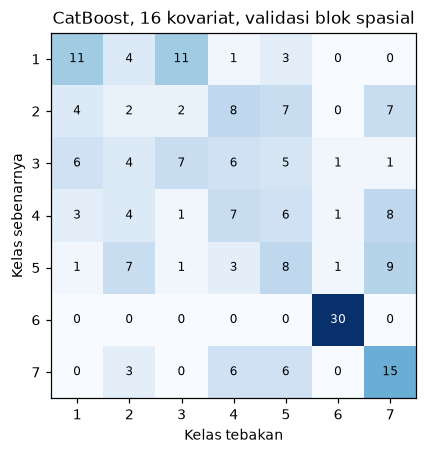

,Material,Titik,Recall (producer's accuracy),Presisi (user's accuracy),F1
kode,,,,,
1,Breksi andesit sisipan diorit,30,0.37,0.44,0.40
2,Breksi andesit teralterasi,30,0.07,0.08,0.07
3,"Breksi andesit teralterasi, ditumpangi lapukan...",30,0.23,0.32,0.27
4,Breksi vulkanik,30,0.23,0.23,0.23
5,"Endapan material Sumbing Muda, pasir tufan, tu...",30,0.27,0.23,0.25
6,Endapan Sumbing Muda dan endapan material longsor,30,1.00,0.91,0.95
7,Tuff pasiran,30,0.50,0.38,0.43


In [14]:
def gambar_matriks(mk, judul, berkas):
    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    ax.imshow(mk / mk.sum(axis=1, keepdims=True), cmap='Blues', vmin=0, vmax=1)
    for i in range(len(KELAS)):
        for j in range(len(KELAS)):
            ax.text(j, i, mk[i, j], ha='center', va='center', fontsize=8, color='white' if mk[i, j] > 15 else 'black')
    ax.set_xticks(range(len(KELAS)), KELAS.index); ax.set_yticks(range(len(KELAS)), KELAS.index)
    ax.set(xlabel='Kelas tebakan', ylabel='Kelas sebenarnya', title=judul)
    plt.tight_layout(); plt.savefig(berkas, dpi=150); plt.show()

def laporan_per_kelas(y, p):
    return pd.DataFrame({'Material': KELAS, 'Titik': np.bincount(y, minlength=len(KELAS) + 1)[1:],
                         "Recall (producer's accuracy)": recall_score(y, p, labels=KELAS.index, average=None, zero_division=0),
                         "Presisi (user's accuracy)": precision_score(y, p, labels=KELAS.index, average=None, zero_division=0),
                         'F1': f1_score(y, p, labels=KELAS.index, average=None, zero_division=0)}, index=KELAS.index).round(2)

p_cb = hasil_cv[('CatBoost', 'Blok spasial')][0]
gambar_matriks(confusion_matrix(y, p_cb, labels=KELAS.index), 'CatBoost, 16 kovariat, validasi blok spasial', 'hasil/matriks_kebingungan.png')
laporan_per_kelas(y, p_cb)

## C4. Memilih kovariat: tingkat kepentingan dan korelasi Pearson

Kovariat untuk model akhir dipilih dengan dua informasi:

1. **Tingkat kepentingan** (*variable importance*), dihitung dengan permutasi (*permutation importance*): nilai satu kovariat di data uji diacak, lalu diukur seberapa besar akurasi turun. Semakin besar penurunannya, semakin penting kovariat itu bagi model. Permutasi dilakukan pada lipatan blok spasial, yaitu pada data yang tidak dipakai melatih model, karena kepentingan yang dihitung dari data latih dapat memberi nilai tinggi pada kovariat yang hanya membantu model menghafal (Meyer et al., 2019).
2. **Korelasi Pearson** dari Bagian B2, untuk menemukan kovariat yang saling menggantikan.

Sebagai perbandingan, ditampilkan pula kepentingan bawaan CatBoost (*built-in feature importance*, PredictionValuesChange), yang dihitung dari data latih.

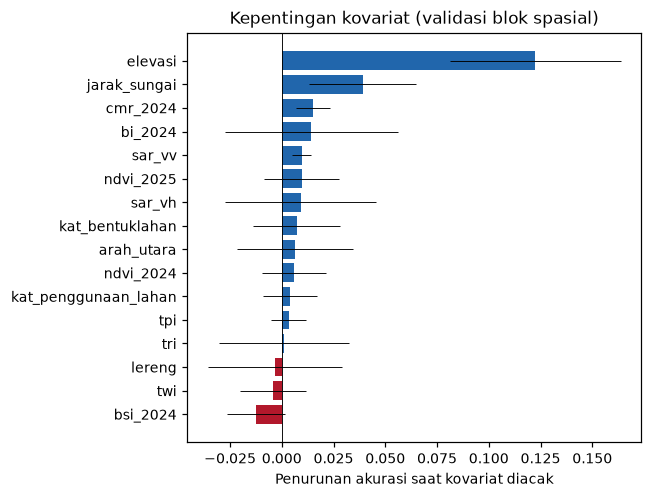

,Permutasi,Simpangan antarlipatan,Bawaan CatBoost (%)
elevasi,0.122,0.041,22.506
jarak_sungai,0.039,0.026,12.450
cmr_2024,0.015,0.008,3.709
bi_2024,0.014,0.042,6.912
sar_vv,0.010,0.004,5.299
ndvi_2025,0.010,0.018,3.367
sar_vh,0.009,0.037,5.339
kat_bentuklahan,0.007,0.021,3.961
arah_utara,0.006,0.028,6.066
ndvi_2024,0.006,0.015,4.552


In [15]:
def kepentingan_permutasi(model, X, y_uji, ulang=10, seed=0):
    """Penurunan akurasi rata-rata saat satu kovariat diacak."""
    rng = np.random.default_rng(seed)
    dasar = accuracy_score(y_uji, model.predict(X))
    turun = {}
    for k in X.columns:
        nilai = []
        for _ in range(ulang):
            Xp = X.copy()
            Xp[k] = rng.permutation(Xp[k].values)
            nilai.append(dasar - accuracy_score(y_uji, model.predict(Xp)))
        turun[k] = np.mean(nilai)
    return pd.Series(turun)

model_cb = hasil_cv[('CatBoost', 'Blok spasial')][2]
per_lipatan = pd.DataFrame([kepentingan_permutasi(m, X_semua.iloc[uji], y[uji]) for m, (_, uji) in zip(model_cb, iris['Blok spasial'])])
bawaan = pd.DataFrame([m.m.get_feature_importance() for m in model_cb], columns=semua).mean()
kepentingan = pd.DataFrame({'Permutasi': per_lipatan.mean(), 'Simpangan antarlipatan': per_lipatan.std(),
                            'Bawaan CatBoost (%)': bawaan}).sort_values('Permutasi', ascending=False)

fig, ax = plt.subplots(figsize=(6, 4.6))
urut = kepentingan.iloc[::-1]
ax.barh(urut.index, urut['Permutasi'], xerr=urut['Simpangan antarlipatan'], color=['#b2182b' if v <= 0 else '#2166ac' for v in urut['Permutasi']], error_kw={'lw': .6})
ax.axvline(0, color='k', lw=.6); ax.set(xlabel='Penurunan akurasi saat kovariat diacak', title='Kepentingan kovariat (validasi blok spasial)')
plt.tight_layout(); plt.savefig('hasil/kepentingan_kovariat.png', dpi=150); plt.show()
kepentingan.round(3)

Aturan pemilihan:

1. Urutkan kovariat menurut kepentingan permutasi, dari yang terbesar.
2. Buang kovariat yang kepentingannya ≤ 0, karena mengacaknya tidak menurunkan akurasi pada data yang belum pernah dilihat model.
3. Telusuri dari atas. Kovariat numerik yang berkorelasi |r| ≥ 0,8 dengan kovariat yang sudah terpilih dibuang, sehingga dari setiap pasangan yang mirip hanya yang lebih penting yang dipertahankan.

Kovariat kategorik hanya diperiksa dengan aturan 2.

In [16]:
def pilih_kovariat(kepentingan_permutasi, r, ambang=AMBANG_R):
    terpilih, keputusan = [], {}
    for k, v in kepentingan_permutasi.sort_values(ascending=False).items():
        if v <= 0:
            keputusan[k] = f'dibuang: kepentingan <= 0 ({v:.4f})'
            continue
        lawan = [t for t in terpilih if k in r.index and t in r.index and abs(r.loc[k, t]) >= ambang]
        if lawan:
            keputusan[k] = f'dibuang: r = {r.loc[k, lawan[0]]:.2f} dengan {lawan[0]} yang lebih penting'
            continue
        terpilih.append(k)
        keputusan[k] = 'dipakai'
    return terpilih, keputusan

terpilih, keputusan = pilih_kovariat(kepentingan['Permutasi'], r_pix)
hasil_terpilih = {skema: validasi(CatBoostKategori, terpilih, skema) for skema in ['Acak', 'Blok spasial']}
banding = []
for label, kolom, sumber in [('Semua kovariat', semua, {s: hasil_cv[('CatBoost', s)] for s in hasil_terpilih}), ('Kovariat terpilih', terpilih, hasil_terpilih)]:
    for skema in hasil_terpilih:
        banding.append({'Kovariat': label, 'Jumlah': len(kolom), 'Validasi': skema, **ukuran(y, sumber[skema][0])})
print('Kovariat terpilih:', terpilih)
display(pd.Series(keputusan, name='Keputusan').to_frame())
pd.DataFrame(banding).round(2)

Kovariat terpilih: ['elevasi', 'jarak_sungai', 'cmr_2024', 'bi_2024', 'sar_vv', 'ndvi_2025', 'sar_vh', 'kat_bentuklahan', 'arah_utara', 'kat_penggunaan_lahan', 'tpi', 'tri']


,Keputusan
elevasi,dipakai
jarak_sungai,dipakai
cmr_2024,dipakai
bi_2024,dipakai
sar_vv,dipakai
ndvi_2025,dipakai
sar_vh,dipakai
kat_bentuklahan,dipakai
arah_utara,dipakai
ndvi_2024,dibuang: r = -0.83 dengan bi_2024 yang lebih p...


,Kovariat,Jumlah,Validasi,Akurasi,Kappa,Presisi makro,Recall makro,F1 makro
0,Semua kovariat,16,Acak,0.48,0.39,0.45,0.48,0.46
1,Semua kovariat,16,Blok spasial,0.38,0.28,0.37,0.38,0.37
2,Kovariat terpilih,12,Acak,0.53,0.46,0.50,0.53,0.51
3,Kovariat terpilih,12,Blok spasial,0.40,0.29,0.38,0.40,0.39


**Catatan kejujuran.** Kovariat di atas dipilih memakai lipatan yang sama dengan yang dipakai untuk menilainya, sehingga angka "Kovariat terpilih" sedikit optimistis. Cara yang ketat adalah memilih kovariat di dalam setiap lipatan, hanya dari data latihnya (*nested cross-validation*). Sel berikut melakukannya. Perhatikan juga apakah kovariat yang terpilih sama dari satu lipatan ke lipatan lain.

In [17]:
p_nested, pilihan_per_lipatan = np.zeros(len(y), int), []
for latih, uji in iris['Blok spasial']:
    imp = []
    for a, b in GroupKFold(4).split(latih, y[latih], groups=blok[latih]):
        m = CatBoostKategori().fit(X_semua.iloc[latih[a]], y[latih[a]])
        imp.append(kepentingan_permutasi(m, X_semua.iloc[latih[b]], y[latih[b]], ulang=5))
    pilih, _ = pilih_kovariat(pd.DataFrame(imp).mean(), r_pix)
    pilihan_per_lipatan.append(pilih)
    X_pilih = siapkan_X(tabel, pilih)
    p_nested[uji] = CatBoostKategori().fit(X_pilih.iloc[latih], y[latih]).predict(X_pilih.iloc[uji])
print('Nested, validasi blok spasial:', {k: round(v, 2) for k, v in ukuran(y, p_nested).items()})
for i, s in enumerate(pilihan_per_lipatan, 1):
    print(f'Lipatan {i}: {len(s)} kovariat, {s}')

Nested, validasi blok spasial: {'Akurasi': 0.37, 'Kappa': 0.27, 'Presisi makro': 0.35, 'Recall makro': 0.37, 'F1 makro': 0.36}
Lipatan 1: 10 kovariat, ['elevasi', 'jarak_sungai', 'sar_vv', 'kat_bentuklahan', 'bi_2024', 'twi', 'arah_utara', 'lereng', 'kat_penggunaan_lahan', 'cmr_2024']
Lipatan 2: 7 kovariat, ['elevasi', 'jarak_sungai', 'bi_2024', 'cmr_2024', 'kat_bentuklahan', 'lereng', 'kat_penggunaan_lahan']
Lipatan 3: 5 kovariat, ['elevasi', 'jarak_sungai', 'bi_2024', 'arah_utara', 'ndvi_2025']
Lipatan 4: 6 kovariat, ['elevasi', 'bi_2024', 'sar_vv', 'jarak_sungai', 'arah_utara', 'kat_penggunaan_lahan']
Lipatan 5: 7 kovariat, ['elevasi', 'jarak_sungai', 'sar_vv', 'sar_vh', 'bi_2024', 'kat_penggunaan_lahan', 'twi']


## C5. Bagaimana jika datanya tidak seimbang (*imbalanced data*)?

Data latihan ini sengaja seimbang: setiap kelas memiliki 30 titik. Di lapangan keadaan itu jarang terjadi. Bila titik disebar acak di seluruh kebun, jumlah titik setiap kelas kira-kira sebanding dengan luasnya, sehingga kelas yang sempit hanya memperoleh sedikit titik. Model lalu cenderung mengabaikan kelas tersebut, karena salah menebaknya hampir tidak menurunkan akurasi keseluruhan.

Sel berikut menirukan keadaan itu. Pada setiap lipatan blok spasial, titik latih dikurangi sehingga jumlahnya sebanding dengan luas kelas pada peta acuan, sedangkan data uji tidak diubah. Tiga cara dibandingkan:

1. **Tanpa penanganan**.
2. **Bobot kelas** (*class weighting*), yaitu kesalahan pada kelas yang sedikit titiknya diberi bobot lebih besar. CatBoost menyediakannya lewat `auto_class_weights='Balanced'`: bobot setiap kelas sama dengan jumlah titik kelas terbanyak dibagi jumlah titik kelas itu.
3. **SMOTE-NC** (*Synthetic Minority Over-sampling Technique–Nominal Continuous*), yaitu titik sintetis (*synthetic samples*) dibuat untuk kelas yang sedikit dengan menginterpolasi antara sebuah titik dan tetangganya di ruang kovariat (Chawla et al., 2002). Akhiran NC berarti kovariat kategorik ikut ditangani: titik sintetis mengambil kategori yang paling sering di antara tetangganya.

Penyeimbangan (*resampling*) **hanya** dilakukan pada data latih setiap lipatan. Jika titik sintetis dibuat sebelum data dibagi, informasi dari titik uji ikut masuk ke data latih (*data leakage*) dan akurasinya menjadi semu. Untuk sasaran kontinu, misalnya nilai C-organik tinggi yang jarang dijumpai, padanannya adalah SMOGN (*SMOTE for regression with Gaussian noise*; Branco et al., 2017).

Contoh jumlah titik latih per kelas setelah dikurangi: {1: 1, 2: 30, 3: 15, 4: 12, 5: 20, 6: 11, 7: 11}


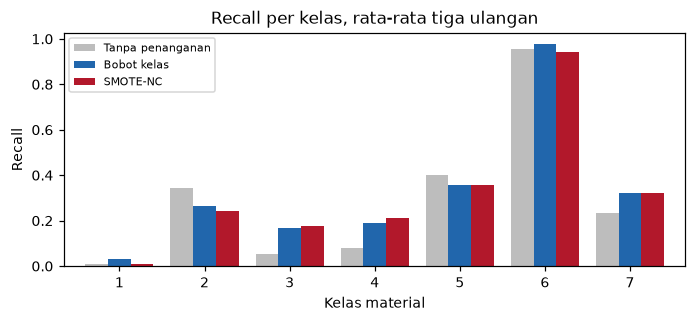

kode,1,2,3,4,5,6,7
Tanpa penanganan,0.01,0.34,0.06,0.08,0.40,0.96,0.23
Bobot kelas,0.03,0.27,0.17,0.19,0.36,0.98,0.32
SMOTE-NC,0.01,0.24,0.18,0.21,0.36,0.94,0.32


,Akurasi,Kappa,Presisi makro,Recall makro,F1 makro
Cara,,,,,
Tanpa penanganan,0.30,0.18,0.31,0.30,0.27
Bobot kelas,0.33,0.22,0.33,0.33,0.31
SMOTE-NC,0.32,0.21,0.31,0.32,0.31


In [18]:
porsi = luas_ha / luas_ha.max()

def kurangi_sebanding_luas(idx, seed):
    """Ambil sebagian titik dari idx sehingga jumlah per kelas sebanding dengan luas kelas."""
    rng = np.random.default_rng(seed)
    simpan = []
    for k in KELAS.index:
        anggota = idx[y[idx] == k]
        n = max(1, int(round(len(anggota) * porsi[k])))
        simpan.extend(rng.choice(anggota, n, replace=False))
    return np.sort(simpan)

def smote_nc(X, yy):
    """Tambah titik sintetis sampai setiap kelas sama banyak dengan kelas terbanyak."""
    jumlah = pd.Series(yy).value_counts()
    sasaran = {k: jumlah.max() for k, n in jumlah.items() if 2 <= n < jumlah.max()}   # kelas dengan 1 titik tidak dapat diinterpolasi
    if not sasaran:
        return X, yy
    k_tetangga = min(5, min(jumlah[k] for k in sasaran) - 1)
    kolom_kat = [i for i, c in enumerate(X.columns) if c in KAT]
    if kolom_kat:
        alat = SMOTENC(categorical_features=kolom_kat, sampling_strategy=sasaran, k_neighbors=k_tetangga, random_state=0)
    else:
        alat = SMOTE(sampling_strategy=sasaran, k_neighbors=k_tetangga, random_state=0)
    return alat.fit_resample(X, yy)

X_t = siapkan_X(tabel, terpilih)
CARA = ['Tanpa penanganan', 'Bobot kelas', 'SMOTE-NC']
rekap, recall_kelas = [], []
for ulang in range(3):
    p = {c: np.zeros(len(y), int) for c in CARA}
    for latih, uji in iris['Blok spasial']:
        s = kurangi_sebanding_luas(latih, ulang)
        p['Tanpa penanganan'][uji] = CatBoostKategori().fit(X_t.iloc[s], y[s]).predict(X_t.iloc[uji])
        p['Bobot kelas'][uji] = CatBoostKategori(auto_class_weights='Balanced').fit(X_t.iloc[s], y[s]).predict(X_t.iloc[uji])
        Xs, ys = smote_nc(X_t.iloc[s].reset_index(drop=True), y[s])
        p['SMOTE-NC'][uji] = CatBoostKategori().fit(Xs, ys).predict(X_t.iloc[uji])
    for c in CARA:
        rekap.append({'Cara': c, **ukuran(y, p[c])})
        recall_kelas.append(pd.Series(recall_score(y, p[c], labels=KELAS.index, average=None), index=KELAS.index, name=c))
contoh = kurangi_sebanding_luas(iris['Blok spasial'][0][0], 0)
print('Contoh jumlah titik latih per kelas setelah dikurangi:', pd.Series(y[contoh]).value_counts().sort_index().to_dict())
recall_rata = pd.concat(recall_kelas, axis=1).T.groupby(level=0).mean().loc[CARA]
fig, ax = plt.subplots(figsize=(6.4, 3))
recall_rata.T.plot.bar(ax=ax, color=['#bdbdbd', '#2166ac', '#b2182b'], width=.8)
ax.set(xlabel='Kelas material', ylabel='Recall', title='Recall per kelas, rata-rata tiga ulangan'); ax.legend(fontsize=7)
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig('hasil/recall_data_tidak_seimbang.png', dpi=150); plt.show()
display(recall_rata.round(2))
pd.DataFrame(rekap).groupby('Cara').mean().loc[CARA].round(2)

Penyeimbangan juga mengubah **luas** setiap kelas pada peta. Sel berikut melatih model dengan seluruh titik yang dikurangi sebanding luas, lalu membandingkan proporsi kelas pada peta hasilnya dengan peta acuan. Baris pertama memakai sampel seimbang 30 titik per kelas seperti pada model akhir.

In [19]:
X_piksel_t = siapkan_X(piksel, terpilih)
s = kurangi_sebanding_luas(np.arange(len(y)), 0)
Xs, ys = smote_nc(X_t.iloc[s].reset_index(drop=True), y[s])
pilihan = {'Sampel seimbang (30 per kelas)': CatBoostKategori().fit(X_t, y),
           'Sebanding luas, tanpa penanganan': CatBoostKategori().fit(X_t.iloc[s], y[s]),
           'Sebanding luas, bobot kelas': CatBoostKategori(auto_class_weights='Balanced').fit(X_t.iloc[s], y[s]),
           'Sebanding luas, SMOTE-NC': CatBoostKategori().fit(Xs, ys)}
proporsi = {'Peta acuan': luas_ha / luas_ha.sum()}
for nama, m in pilihan.items():
    proporsi[nama] = pd.Series(m.predict(X_piksel_t)).value_counts(normalize=True).reindex(KELAS.index, fill_value=0)
(100 * pd.DataFrame(proporsi).T).round(1)

kode,1,2,3,4,5,6,7
Peta acuan,3.3,25.6,13.0,13.5,22.9,12.0,9.7
Sampel seimbang (30 per kelas),10.2,13.3,18.7,14.2,15.1,14.3,14.2
"Sebanding luas, tanpa penanganan",0.5,34.4,12.7,9.1,24.5,14.0,4.9
"Sebanding luas, bobot kelas",2.7,24.5,16.7,11.1,21.7,15.1,8.2
"Sebanding luas, SMOTE-NC",3.2,23.7,16.0,13.7,19.4,14.6,9.3


## C6. Model akhir dan peta tutupan material

Model akhir adalah CatBoost dengan kovariat terpilih. Ketelitiannya tidak dapat dinilai dari titik yang dipakai untuk melatihnya, sehingga yang dilaporkan adalah hasil validasi blok spasial dengan kovariat dan pengaturan yang sama (Bagian C4). Inilah penilaian ketelitian yang lazim menyertai sebuah peta kelas: matriks kebingungan, *producer's accuracy* dan *user's accuracy* setiap kelas, serta ukuran keseluruhannya.

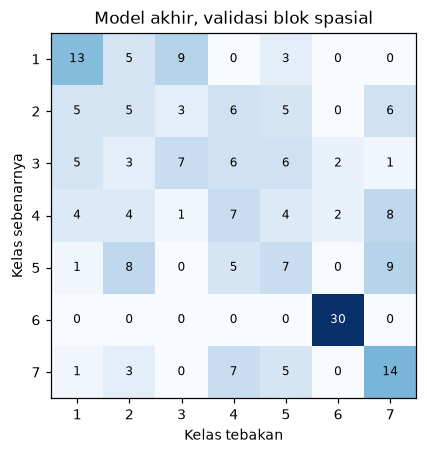

Ukuran keseluruhan: {'Akurasi': 0.4, 'Kappa': 0.29, 'Presisi makro': 0.38, 'Recall makro': 0.4, 'F1 makro': 0.39}


,Material,Titik,Recall (producer's accuracy),Presisi (user's accuracy),F1
kode,,,,,
1,Breksi andesit sisipan diorit,30,0.43,0.45,0.44
2,Breksi andesit teralterasi,30,0.17,0.18,0.17
3,"Breksi andesit teralterasi, ditumpangi lapukan...",30,0.23,0.35,0.28
4,Breksi vulkanik,30,0.23,0.23,0.23
5,"Endapan material Sumbing Muda, pasir tufan, tu...",30,0.23,0.23,0.23
6,Endapan Sumbing Muda dan endapan material longsor,30,1.00,0.88,0.94
7,Tuff pasiran,30,0.47,0.37,0.41


In [20]:
p_akhir = hasil_terpilih['Blok spasial'][0]
gambar_matriks(confusion_matrix(y, p_akhir, labels=KELAS.index), 'Model akhir, validasi blok spasial', 'hasil/matriks_kebingungan_model_akhir.png')
laporan_akhir = laporan_per_kelas(y, p_akhir)
laporan_akhir.to_csv('hasil/laporan_per_kelas_model_akhir.csv')
print('Ukuran keseluruhan:', {k: round(v, 2) for k, v in ukuran(y, p_akhir).items()})
laporan_akhir

Peta dibuat dengan melatih model yang sama pada seluruh 210 titik. Setiap piksel memperoleh kelas dengan peluang tertinggi beserta nilai peluang itu.

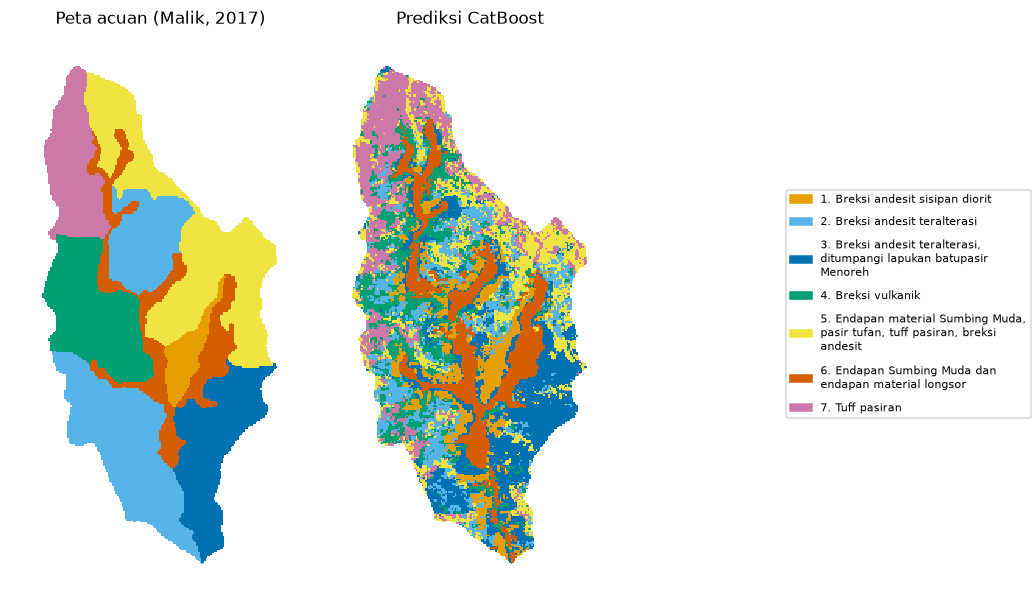

Kesesuaian dengan peta acuan: 46.1% piksel


,Material,Acuan (ha),Prediksi (ha),Kesesuaian per kelas acuan (%)
kode,,,,
1,Breksi andesit sisipan diorit,9.7,30.2,66.9
2,Breksi andesit teralterasi,75.5,39.2,25.9
3,"Breksi andesit teralterasi, ditumpangi lapukan...",38.2,55.1,65.8
4,Breksi vulkanik,39.8,41.8,35.0
5,"Endapan material Sumbing Muda, pasir tufan, tu...",67.4,44.4,33.7
6,Endapan Sumbing Muda dan endapan material longsor,35.4,42.1,89.6
7,Tuff pasiran,28.7,42.0,56.9


In [21]:
model_akhir = pilihan['Sampel seimbang (30 per kelas)']
P = model_akhir.predict_proba(X_piksel_t)            # peluang setiap kelas untuk setiap piksel
kelas_piksel = np.asarray(model_akhir.classes_)[P.argmax(axis=1)]
peluang_maks = P.max(axis=1)
entropi = -(P * np.log(np.clip(P, 1e-12, 1))).sum(axis=1) / np.log(P.shape[1])

def ke_peta(nilai):
    peta = np.full((tinggi, lebar), np.nan, dtype='float32')
    peta[dalam] = nilai
    return peta

def simpan(peta, nama, kelas=False):
    """Simpan GeoTIFF. Peta kelas disimpan sebagai bilangan bulat dengan nodata 0."""
    isi = np.nan_to_num(peta, nan=0 if kelas else -9999).astype('uint8' if kelas else 'float32')
    with rasterio.open(f'hasil/{nama}.tif', 'w', driver='GTiff', height=tinggi, width=lebar, count=1, dtype=isi.dtype,
                       crs=crs, transform=transform, nodata=0 if kelas else -9999, compress='deflate') as d:
        d.write(isi, 1)

peta_kelas = ke_peta(kelas_piksel)
simpan(peta_kelas, 'prediksi_material', kelas=True)
# gaya QGIS peta acuan dipakai ulang, agar peta prediksi tampil dengan warna dan nama kelas yang sama
shutil.copy('material_acuan_10m.qml', 'hasil/prediksi_material.qml')
simpan(ke_peta(peluang_maks), 'peluang_maks_material')
simpan(ke_peta(entropi), 'entropi_material')

fig, ax = plt.subplots(1, 2, figsize=(10, 5.6))
ax[0].imshow(np.where(dalam, acuan, np.nan), cmap=PETA_WARNA, vmin=.5, vmax=7.5, interpolation='nearest'); ax[0].set_title('Peta acuan (Malik, 2017)')
ax[1].imshow(peta_kelas, cmap=PETA_WARNA, vmin=.5, vmax=7.5, interpolation='nearest'); ax[1].set_title('Prediksi CatBoost')
for a in ax: a.axis('off')
fig.legend(handles=[Patch(color=WARNA[k], label=textwrap.fill(f'{k}. {v}', 34)) for k, v in KELAS.items()], loc='center right', fontsize=7, labelspacing=1)
plt.tight_layout(rect=(0, 0, .7, 1)); plt.savefig('hasil/peta_prediksi_material.png', dpi=150); plt.show()

sama = kelas_piksel == acuan[dalam]
print(f'Kesesuaian dengan peta acuan: {100 * sama.mean():.1f}% piksel')
pd.DataFrame({'Material': KELAS, 'Acuan (ha)': luas_ha.round(1),
              'Prediksi (ha)': (pd.Series(kelas_piksel).value_counts().reindex(KELAS.index, fill_value=0) * 100 / 1e4).round(1),
              'Kesesuaian per kelas acuan (%)': [round(100 * sama[acuan[dalam] == k].mean(), 1) for k in KELAS.index]})

Bandingkan luas prediksi dengan luas acuan. Model akhir dilatih dengan jumlah titik yang sama untuk setiap kelas, sehingga model menganggap ketujuh kelas sama umumnya. Akibatnya, kelas yang sempit cenderung diprediksi terlalu luas dan kelas yang luas terlalu sempit. Inilah sisi lain dari persoalan pada Bagian C5.

## C7. Seberapa yakin model, dan apakah keyakinannya dapat dipercaya?

Untuk sasaran kategorik, ketidakpastian (*uncertainty*) dinyatakan dengan peluang kelas (*class probability*). Peluang tertinggi yang rendah berarti model ragu di antara beberapa kelas. Entropi (*entropy*) meringkas sebaran peluang ke semua kelas: 0 berarti model yakin penuh pada satu kelas, sedangkan 1 berarti semua kelas sama mungkin. Peluang itu baru berguna bila jujur atau terkalibrasi (*well-calibrated*), yaitu bila titik yang diprediksi dengan peluang tinggi memang lebih sering benar. Sel berikut memeriksanya dengan prediksi validasi blok spasial.

,Jumlah titik,Proporsi benar
Peluang tertinggi,,
"(-0.001, 0.3]",20,0.15
"(0.3, 0.5]",103,0.29
"(0.5, 0.7]",47,0.38
"(0.7, 1.0]",40,0.80


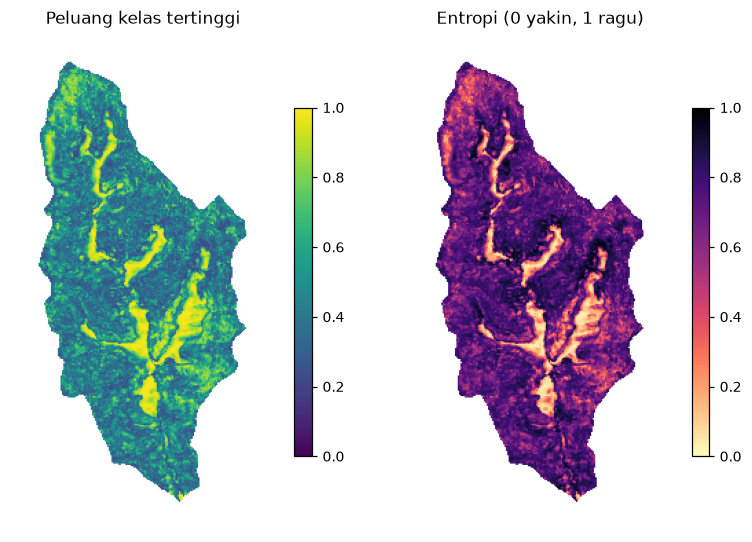

Rata-rata peluang tertinggi 0.51 | piksel dengan peluang >= 0,7: 17.3%


In [22]:
p_t, peluang_t, model_t = hasil_terpilih['Blok spasial']
benar = p_t == y
kelompok = pd.cut(peluang_t.max(axis=1), [0, .3, .5, .7, 1.0], include_lowest=True)
keyakinan = pd.DataFrame({'Peluang tertinggi': kelompok, 'Benar': benar}).groupby('Peluang tertinggi', observed=False)['Benar']
display(keyakinan.agg(['count', 'mean']).rename(columns={'count': 'Jumlah titik', 'mean': 'Proporsi benar'}).round(2))

fig, ax = plt.subplots(1, 2, figsize=(7.4, 5))
a = ax[0].imshow(ke_peta(peluang_maks), cmap='viridis', vmin=0, vmax=1); ax[0].set_title('Peluang kelas tertinggi'); plt.colorbar(a, ax=ax[0], shrink=.7)
b = ax[1].imshow(ke_peta(entropi), cmap='magma_r', vmin=0, vmax=1); ax[1].set_title('Entropi (0 yakin, 1 ragu)'); plt.colorbar(b, ax=ax[1], shrink=.7)
for x in ax: x.axis('off')
plt.tight_layout(); plt.savefig('hasil/peta_peluang_entropi.png', dpi=150); plt.show()
print(f'Rata-rata peluang tertinggi {peluang_maks.mean():.2f} | piksel dengan peluang >= 0,7: {100 * (peluang_maks >= .7).mean():.1f}%')

## C8. Wilayah keberlakuan model (*area of applicability*)

Indeks ketidakmiripan (*dissimilarity index*, DI) mengukur jarak setiap piksel ke titik latih terdekat dalam ruang kovariat. Mengikuti Meyer dan Pebesma (2021), setiap kovariat diberi bobot sesuai kepentingannya dari Bagian C4, sehingga kovariat yang tidak berpengaruh tidak ikut menentukan. Di sini hanya kovariat numerik yang dipakai. Ambangnya diturunkan dari DI titik latih terhadap titik di lipatan blok lain. Ini penerapan sederhana untuk peragaan.

Ambang DI 0.31 | 97.8% piksel berada di dalam wilayah keberlakuan


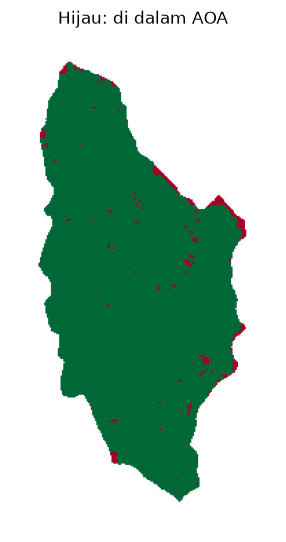

In [23]:
num_t = [k for k in terpilih if k in numerik]
bobot = kepentingan.loc[num_t, 'Permutasi'].clip(lower=0).values
skala = StandardScaler().fit(tabel[num_t])
Zt, Zp = skala.transform(tabel[num_t]) * bobot, skala.transform(piksel[num_t]) * bobot
d_rata = NearestNeighbors(n_neighbors=len(Zt)).fit(Zt).kneighbors(Zt)[0][:, 1:].mean()
lipatan = np.zeros(len(y), int)
for i, (_, uji) in enumerate(iris['Blok spasial']):
    lipatan[uji] = i
di_titik = np.array([np.linalg.norm(Zt[lipatan != lipatan[i]] - Zt[i], axis=1).min() for i in range(len(Zt))]) / d_rata
ambang = np.percentile(di_titik, 75) + 1.5 * (np.percentile(di_titik, 75) - np.percentile(di_titik, 25))
di_piksel = NearestNeighbors(n_neighbors=1).fit(Zt).kneighbors(Zp)[0].ravel() / d_rata
aoa = (di_piksel <= ambang).astype('float32')
simpan(ke_peta(di_piksel), 'di_material')
simpan(ke_peta(aoa), 'aoa_material')
print(f'Ambang DI {ambang:.2f} | {100 * aoa.mean():.1f}% piksel berada di dalam wilayah keberlakuan')
plt.figure(figsize=(3.8, 5)); plt.imshow(ke_peta(aoa), cmap='RdYlGn', vmin=0, vmax=1); plt.axis('off'); plt.title('Hijau: di dalam AOA')
plt.tight_layout(); plt.savefig('hasil/aoa.png', dpi=150); plt.show()

## C9. Di mana model salah?

Peta kesesuaian (*agreement map*) membandingkan peta prediksi dengan peta acuan piksel demi piksel. Titik menunjukkan hasil validasi blok spasial, yaitu benar atau salahnya tebakan saat blok titik itu disisihkan. Perhatikan apakah kesalahan mengumpul di kelas tertentu, di dekat batas kelas, atau di bagian wilayah tertentu.

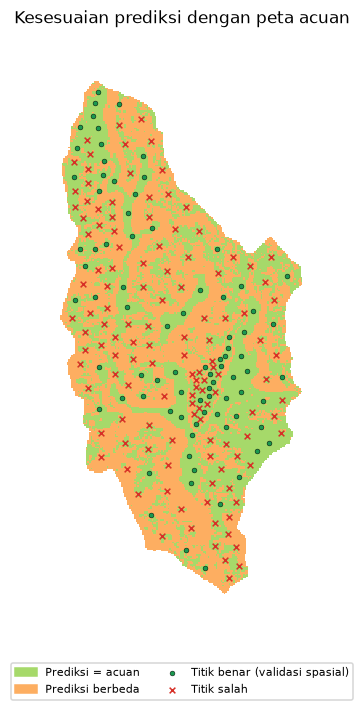

,Material,Titik salah (validasi spasial)
kode,,
1,Breksi andesit sisipan diorit,17
2,Breksi andesit teralterasi,25
3,"Breksi andesit teralterasi, ditumpangi lapukan...",23
4,Breksi vulkanik,23
5,"Endapan material Sumbing Muda, pasir tufan, tu...",23
6,Endapan Sumbing Muda dan endapan material longsor,0
7,Tuff pasiran,16


In [24]:
kesesuaian = ke_peta(np.where(sama, 1, 2))
simpan(kesesuaian, 'kesesuaian_material', kelas=True)
fig, ax = plt.subplots(figsize=(4.6, 6.4))
ax.imshow(kesesuaian, extent=luasan, cmap=ListedColormap(['#a6d96a', '#fdae61']), vmin=.5, vmax=2.5, interpolation='nearest')
ax.scatter(titik.x[benar], titik.y[benar], s=10, c='#1a9850', edgecolor='k', lw=.3, label='Titik benar (validasi spasial)')
ax.scatter(titik.x[~benar], titik.y[~benar], s=14, c='#d73027', marker='x', lw=1, label='Titik salah')
fig.legend(handles=[Patch(color='#a6d96a', label='Prediksi = acuan'), Patch(color='#fdae61', label='Prediksi berbeda')] + ax.get_legend_handles_labels()[0], fontsize=7, loc='lower center', ncol=2)
ax.axis('off'); ax.set_title('Kesesuaian prediksi dengan peta acuan')
plt.tight_layout(rect=(0, .08, 1, 1)); plt.savefig('hasil/kesesuaian_dan_kesalahan.png', dpi=150); plt.show()
pd.DataFrame({'Material': KELAS, 'Titik salah (validasi spasial)': pd.Series(y[~benar]).value_counts().reindex(KELAS.index, fill_value=0)})

## Yang dibawa ke QGIS dan ke presentasi

Folder `hasil/` kini berisi peta kelas (`prediksi_material.tif`), peta peluang dan entropi, DI, AOA, peta kesesuaian, tabel metrik, dan gambar. Buka GeoTIFF-nya di QGIS (Modul Praktik 5, tahap terakhir), tumpangkan dengan peta SMU dari Praktik 2, lalu siapkan jawaban untuk pertanyaan berikut:

1. Seberapa baik CatBoost dibandingkan pembanding sederhananya, dan pada skema validasi yang mana?
2. Kelas mana yang paling sering tertukar, dan di mana peta ini paling tidak dapat dipercaya?
3. Jika sampel di kebun tidak seimbang, cara penanganan mana yang dipilih, dan apa akibatnya pada luas setiap kelas di peta?